In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,StandardScaler,LabelEncoder,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from collections import Counter
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN

In [10]:
df = pd.read_csv(r"C:\Users\sreya\Desktop\Fraud Detection Assignments\customers-10000.csv")

In [11]:
df = df.dropna()
print(df.shape)

(10000, 12)


In [12]:
print(list(df.columns))

['Index', 'Customer Id', 'First Name', 'Last Name', 'Company', 'City', 'Country', 'Phone 1', 'Phone 2', 'Email', 'Subscription Date', 'Website']


# Partition

In [13]:
split_fraction = 0.70
partition = df.sample(frac=split_fraction, random_state=42)
len(partition)

7000

# Random 

In [14]:
sample_random = df.sample(n=100)
sample_random.head()

,Index,Customer Id,First Name,Last Name,Company,City,Country,Phone 1,Phone 2,Email,Subscription Date,Website
4925,4926,C9BF6C5dF2a6Bd5,Duane,Poole,"Gonzales, Horn and Gonzales",Allisonbury,Tajikistan,(027)068-2008x548,658.848.5227,gavin22@harmon.biz,2021-06-14,https://www.aguilar.com/
4567,4568,Fce60568960e726,Mackenzie,Murphy,Beasley-Kim,Lake David,Montserrat,+1-551-970-1239x71090,651-644-7495,vwebb@hoover.net,2021-12-25,http://www.dunn.net/
9530,9531,852EcBb482A8d11,Ariel,Cline,"Diaz, Kirby and Mathis",East Feliciaville,Cote d'Ivoire,360-507-4139x546,+1-312-291-6585x47109,pattykey@simmons.com,2020-04-23,https://shepard.biz/
4245,4246,dD66836c1066a8f,Marc,Rasmussen,Kent-Pineda,Odonnellstad,Myanmar,+1-127-059-9660x326,929.270.7677x2890,alexsharp@bonilla-carpenter.org,2021-08-22,http://www.cox.biz/
3553,3554,DA5F5eEf4Bcc7Af,Ivan,Good,Sherman-Arias,Gilesfurt,Japan,033-937-6335x822,001-776-284-6420,floydjoy@walls-vance.com,2021-09-24,https://www.braun.com/


# stratified

In [15]:
sample_stratified = (
    df.groupby("Country")
      .apply(lambda x: x.sample(frac=0.1))
)
sample_stratified.head()
#sample_stratified.count()
#print(sample_stratified["Country"].value_counts())

C:\Users\sreya\AppData\Local\Temp\ipykernel_29400\3849260146.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(frac=0.1))


Index      Customer Id First Name  Last Name  \
Country                                                          
Afghanistan 8419   8420  8c1BeeD30991021   Franklin  Schneider   
            4329   4330  8fd9dF052E8c274     Rhonda       Gill   
            3103   3104  2EfEE3a93E03cec    Rachael       Moss   
            8997   8998  dA13cA63cCFB8A5       Sara      Costa   
Albania     553     554  aE35B96fad807Bc      Tanya    Beasley   

                                         Company                 City  \
Country                                                                 
Afghanistan 8419                     Hopkins Ltd    East Adrienneside   
            4329                   Powers-Brandt  North Catherinestad   
            3103                       Blake LLC            Carolstad   
            8997                    Buck-Chapman         Katrinahaven   
Albania     553   Hopkins, Monroe and Fitzgerald            New Cathy   

                      Country             Phone 1                Phone 2  \
Country                                                                    
Afghanistan 8419  Afghanistan    899.981.6473x857        +1-824-388-5245   
            4329  Afghanistan        533-755-6685          (793)896-7827   
            3103  Afghanistan  262.977.1060x36565  001-554-264-6402x2620   
            8997  Afghanistan    001-542-320-5321       500-274-4271x000   
Albania     553       Albania        599.260.0269    (177)331-7253x46538   

                                         Email Subscription Date  \
Country                                                            
Afghanistan 8419   katherinejennings@mckay.net        2022-02-26   
            4329            bholden@howard.org        2021-09-15   
            3103    scosta@nelson-solomon.info        2021-02-16   
            8997  guerrakenneth@villarreal.biz        2022-05-11   
Albania     553                tlittle@lam.org        2021-08-29   

                                            Website  
Country                                              
Afghanistan 8419         http://dorsey-burgess.biz/  
            4329               https://oconnor.net/  
            3103          http://savage-prince.biz/  
            8997  http://www.chapman-whitehead.com/  
Albania     553     http://www.huffman-preston.com/

## Task 1: Fix Number of Sample (500 only)

In [16]:
sample_500, _ = train_test_split(df, train_size=500, stratify=df["Country"], random_state=42)

print(len(sample_500))
print(sample_500["Country"].value_counts())

500
Country
Korea                                           4
Congo                                           4
Sierra Leone                                    3
Palau                                           3
Isle of Man                                     3
                                               ..
Czech Republic                                  1
Tokelau                                         1
Antarctica (the territory South of 60 deg S)    1
Cocos (Keeling) Islands                         1
Mayotte                                         1
Name: count, Length: 243, dtype: int64


## Task 2: Country-wise list/count

In [17]:
country_count = df["Country"].value_counts()

print("Number of countries:", len(country_count))
print(country_count)

Number of countries: 243
Country
Korea                                           84
Congo                                           81
Vanuatu                                         58
Sierra Leone                                    56
Mauritius                                       54
                                                ..
Suriname                                        27
Mayotte                                         26
Palestinian Territory                           26
Antarctica (the territory South of 60 deg S)    26
New Caledonia                                   26
Name: count, Length: 243, dtype: int64


## Task 3: Equalize the country wise count

In [18]:
min_count = df["Country"].value_counts().min()

sample_equal = df.groupby("Country").sample(n=min_count, random_state=42)

print("Rows per country:", min_count)
print("Total rows:", len(sample_equal))
print(sample_equal["Country"].value_counts())

Rows per country: 26
Total rows: 6318
Country
Afghanistan          26
Albania              26
Algeria              26
American Samoa       26
Andorra              26
                     ..
Wallis and Futuna    26
Western Sahara       26
Yemen                26
Zambia               26
Zimbabwe             26
Name: count, Length: 243, dtype: int64


# Cluster 

In [19]:
countries = df["Country"].unique()
selected_countries = pd.Series(countries).sample(n=2, random_state=42)
sample_cluster = df[df["Country"].isin(selected_countries)]
sample_cluster.head(36)
#sample_cluster.count()

,Index,Customer Id,First Name,Last Name,Company,City,Country,Phone 1,Phone 2,Email,Subscription Date,Website
6,7,3e1187fCcebC8d2,Mathew,Hoffman,"Bender, Pittman and Kidd",West Ralph,Uzbekistan,842.380.1168,(178)178-5447x32603,bauergerald@morrison.com,2020-04-09,http://www.holt.com/
25,26,0748BdEFeb4834F,Mackenzie,Williamson,Hart-Klein,New Maxhaven,Saint Helena,+1-605-640-1833x70183,656.931.4990,zramos@haney.org,2020-03-06,http://www.allison-clements.com/
78,79,e8f4b4D1FcF5Fc3,Joshua,Ortega,"Herman, Preston and Spence",Lake Brittney,Uzbekistan,+1-734-076-1901x55246,001-569-506-8227,robbinsgordon@dyer-kim.info,2021-09-29,http://barr-salas.org/
146,147,BffD8b78EB17aB6,Diamond,Pollard,Hull Group,North Isabellaberg,Uzbekistan,3816437019,614.140.7737x97774,weavermeagan@sampson.com,2020-03-02,https://fox.biz/
170,171,65EfcbFAaBc9755,Steve,Booth,"Cooke, Zuniga and Maldonado",North Glendaborough,Saint Helena,(390)652-3650x10148,995.423.9151x965,perry87@nichols.biz,2021-10-12,https://molina.com/
280,281,Aaf2D8fF5edeD6F,Evelyn,Huynh,Parrish-Simmons,South Sheila,Saint Helena,001-650-421-0322x71656,224.261.4291,jmullins@craig.com,2022-03-23,http://www.ellison-hobbs.com/
583,584,1A6D0cd74F67a5a,Stanley,Shannon,Tucker-Diaz,Laurabury,Saint Helena,9042616723,+1-049-516-0935x212,becky23@nunez.info,2021-09-23,http://frey-rowland.net/
746,747,cf4DAA75cd7AC14,Betty,Soto,Roberson PLC,South Guy,Uzbekistan,3719042212,434-533-6969x900,lcooper@ball-pittman.org,2020-08-29,http://patterson-huerta.com/
854,855,6CFAA9f71E9423B,Judy,Rogers,Meyers and Sons,Cliffordborough,Saint Helena,(181)997-7317,+1-610-634-3284x8288,vernon50@dennis.biz,2021-04-10,http://davenport-jefferson.com/
1046,1047,bb53513a2648c5f,Yvonne,Kramer,"Fleming, Bryan and Pruitt",New Fred,Uzbekistan,001-451-673-4313x2831,+1-344-126-1653x54520,adrienneescobar@krueger.biz,2022-04-02,https://www.benton-escobar.info/


## Task 4: Sample from 5 most/least listed countries  

In [20]:
counts = df["Country"].value_counts()

# All rows from the 5 most listed and 5 least listed countries
sample_top5 = df[df["Country"].isin(counts.head(5).index)]
sample_bottom5 = df[df["Country"].isin(counts.tail(5).index)]

print(sample_top5["Country"].value_counts())
print(sample_bottom5["Country"].value_counts())

Country
Korea           84
Congo           81
Vanuatu         58
Sierra Leone    56
Mauritius       54
Name: count, dtype: int64
Country
Suriname                                        27
Palestinian Territory                           26
Mayotte                                         26
New Caledonia                                   26
Antarctica (the territory South of 60 deg S)    26
Name: count, dtype: int64


## Data Selection

**1. Missing Value**

**2. Identical Values**

**3. Correlation Analysis**

**4. Chi-Square Test**

In [21]:
df = pd.read_csv(r"C:\Users\sreya\Desktop\Fraud Detection Assignments\Fraud Detection Dataset.csv")
print(df.shape)

(51000, 12)


In [25]:
# 1.Missing Values

In [23]:
print(df.isnull().sum())

Transaction_ID                         0
User_ID                                0
Transaction_Amount                  2520
Transaction_Type                       0
Time_of_Transaction                 2552
Device_Used                         2473
Location                            2547
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                      2469
Fraudulent                             0
dtype: int64


In [24]:
df = df.dropna()
print(df.shape)

(39583, 12)


In [26]:
# 2.Identical values 

In [27]:
print(df.nunique())

print("Duplicate rows:", df.duplicated().sum())

Transaction_ID                      38796
User_ID                              4000
Transaction_Amount                  36916
Transaction_Type                        5
Time_of_Transaction                    24
Device_Used                             4
Location                                8
Previous_Fraudulent_Transactions        5
Account_Age                           119
Number_of_Transactions_Last_24H        14
Payment_Method                          5
Fraudulent                              2
dtype: int64
Duplicate rows: 688


In [28]:
df = df.drop_duplicates()
print(df.shape)

(38895, 12)


In [30]:
#correlation analysis

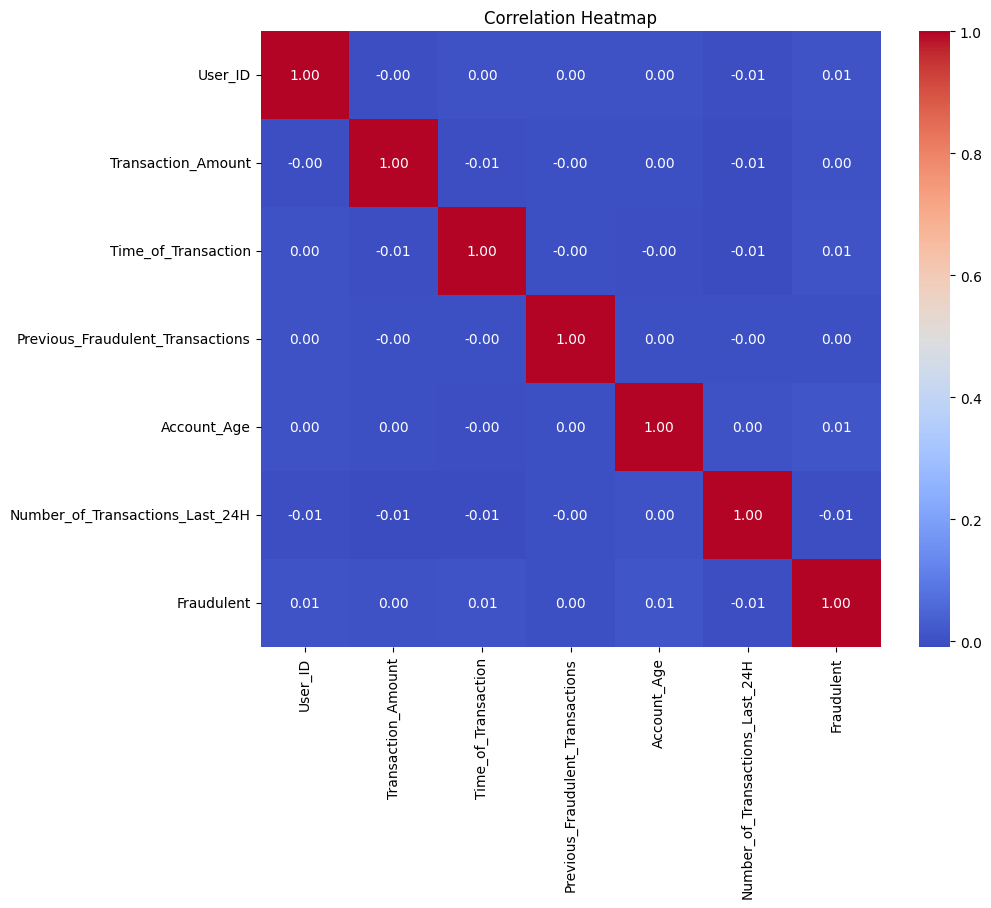

In [29]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [31]:
print(corr["Fraudulent"].sort_values())

Number_of_Transactions_Last_24H    -0.005018
Previous_Fraudulent_Transactions    0.000488
Transaction_Amount                  0.002722
User_ID                             0.008553
Time_of_Transaction                 0.009356
Account_Age                         0.010869
Fraudulent                          1.000000
Name: Fraudulent, dtype: float64


In [32]:
# Chi-Square Test

In [33]:
from sklearn.feature_selection import chi2, SelectKBest

X = df.drop(["Fraudulent", "Transaction_ID", "User_ID"], axis=1)
Y = df["Fraudulent"]

# Convert text columns to numbers
for col in X.select_dtypes("object"):
    X[col] = LabelEncoder().fit_transform(X[col])

selector = SelectKBest(score_func=chi2, k="all")
selector.fit(X, Y)

print(pd.Series(selector.scores_, index=X.columns))

Transaction_Amount                  2465.194824
Transaction_Type                       0.815986
Time_of_Transaction                   14.194094
Device_Used                            0.055325
Location                               6.101231
Previous_Fraudulent_Transactions       0.009285
Account_Age                           90.351405
Number_of_Transactions_Last_24H        2.109518
Payment_Method                         0.237442
dtype: float64


In [34]:
# Features (X) and target (Y)
X = df.drop(["Fraudulent", "Transaction_ID", "User_ID"], axis=1)
Y = df["Fraudulent"]

# Convert text columns to numbers
for col in X.select_dtypes("object"):
    X[col] = LabelEncoder().fit_transform(X[col])

print(X.shape, Y.shape)

(38895, 9) (38895,)


In [ ]:
#Split

In [35]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42, stratify=Y
)

print(X_train.shape, X_test.shape) 

(27226, 9) (11669, 9)


## Task 5: ML Model

In [36]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Scale the features (needed for Logistic Regression and SVM)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC()
}

# Train each model and collect its scores
results = []
for name, model in models.items():
    model.fit(X_train_s, Y_train)
    Y_pred = model.predict(X_test_s)
    results.append([
        name,
        accuracy_score(Y_test, Y_pred),
        precision_score(Y_test, Y_pred, zero_division=0),
        recall_score(Y_test, Y_pred),
        f1_score(Y_test, Y_pred)
    ])

results = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1"])
print(results.round(4))

                 Model  Accuracy  Precision  Recall      F1
0        Decision Tree    0.8953     0.0571  0.0737  0.0643
1        Random Forest    0.9512     1.0000  0.0018  0.0035
2  Logistic Regression    0.9512     0.0000  0.0000  0.0000
3                  SVM    0.9512     0.0000  0.0000  0.0000
